<a href="https://colab.research.google.com/github/yamangakre2007-afks/EDA-PYTHON-CLASS/blob/main/EDA_House_Price_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Project Overview

Title: Exploratory Data Analysis of the Ames Housing Dataset

Dataset: House Prices: Advanced Regression Techniques (Kaggle), file 1,460 rows and 81 columns.

Objective: Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices, and to practise the full EDA workflow.

Step 1: Setup and First Look Goal: Load the data and understand its shape, types, and gaps.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


df = pd.read_csv("train.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Info:")
df.info()

missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})


missing_summary = missing_summary[missing_summary['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False)

print("\nColumns with Missing Values:")
display(missing_summary)

Dataset Shape: (1460, 81)

First 5 Rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64 

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


Step 2: Classify Variables Goal: Split columns into numerical, categorical, and ordinal groups.

In [13]:
import pandas as pd


numeric_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for column, categories in ordinal_map.items():
    df[column] = pd.Categorical(df[column], categories=categories, ordered=True)

summary_data = []
for col in df.columns:

    if col in ordinal_map:
        col_type = 'Ordinal'
    elif col in numeric_cols:
        col_type = 'Numerical'
    elif col in categorical_cols:
        col_type = 'Categorical'
    else:
        col_type = str(df[col].dtype)

    num_unique = df[col].nunique()

    examples = df[col].dropna().unique()[:3].tolist()

    summary_data.append({
        "Column Name": col,
        "Type": col_type,
        "Number of Unique Values": num_unique,
        "Example Values": examples
    })

summary_df = pd.DataFrame(summary_data)


display(summary_df)

,Column Name,Type,Number of Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3]"
1,MSSubClass,Numerical,15,"[60, 20, 70]"
2,MSZoning,Categorical,5,"[RL, RM, C (all)]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9]"
77,YrSold,Numerical,5,"[2008, 2007, 2006]"
78,SaleType,Categorical,9,"[WD, New, COD]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial]"


Step 3: Descriptive Statistics
Goal: Summarise centre and spread.


In [14]:
import numpy as np
import pandas as pd
import scipy.stats as stats


print("Descriptive Statistics for Numeric Columns:")
display(df.describe())

target_cols = ['SalePrice', 'GrLivArea', 'LotArea']
print("\n--- Detailed Metrics for Target Columns ---")

for column in target_cols:
    col_data = df[column].dropna()


    mean_val = col_data.mean()
    median_val = col_data.median()
    try:
        mode_val = col_data.mode().iloc[0]
    except IndexError:
        mode_val = np.nan


    std_val = col_data.std()
    var_val = col_data.var()
    min_val = col_data.min()
    max_val = col_data.max()
    range_val = max_val - min_val

    q1 = col_data.quantile(0.25)
    q3 = col_data.quantile(0.75)
    iqr_val = q3 - q1


    skew_val = col_data.skew()
    kurt_val = col_data.kurtosis()


    print(f"\nMetrics for '{column}':")
    print(f"  Mean: {mean_val:.2f}")
    print(f"  Median: {median_val:.2f}")
    print(f"  Mode: {mode_val:.2f}")
    print(f"  Std Dev: {std_val:.2f}")
    print(f"  Variance: {var_val:.2f}")
    print(f"  Range: {range_val:.2f} (Min: {min_val:.2f}, Max: {max_val:.2f})")
    print(f"  IQR: {iqr_val:.2f} (Q1: {q1:.2f}, Q3: {q3:.2f})")
    print(f"  Skewness: {skew_val:.2f}")
    print(f"  Kurtosis: {kurt_val:.2f}")

    # Shape analysis based on mean vs median comparison
    if mean_val > median_val:
        print("  Note: The distribution is right-skewed (positively skewed).")
    elif mean_val < median_val:
        print("  Note: The distribution is left-skewed (negatively skewed).")
    else:
        print("  Note: The distribution is perfectly symmetrical.")

# 3. Analyze specified categorical columns
print("\n--- Value Counts for Selected Categorical Columns ---")
cat_cols = ['Neighborhood', 'HouseStyle']
for column in cat_cols:
    if column in df.columns:
        print(f"\nValue Counts for '{column}':")
        display(df[column].value_counts())

Descriptive Statistics for Numeric Columns:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000



--- Detailed Metrics for Target Columns ---

Metrics for 'SalePrice':
  Mean: 180921.20
  Median: 163000.00
  Mode: 140000.00
  Std Dev: 79442.50
  Variance: 6311111264.30
  Range: 720100.00 (Min: 34900.00, Max: 755000.00)
  IQR: 84025.00 (Q1: 129975.00, Q3: 214000.00)
  Skewness: 1.88
  Kurtosis: 6.54
  Note: The distribution is right-skewed (positively skewed).

Metrics for 'GrLivArea':
  Mean: 1515.46
  Median: 1464.00
  Mode: 864.00
  Std Dev: 525.48
  Variance: 276129.63
  Range: 5308.00 (Min: 334.00, Max: 5642.00)
  IQR: 647.25 (Q1: 1129.50, Q3: 1776.75)
  Skewness: 1.37
  Kurtosis: 4.90
  Note: The distribution is right-skewed (positively skewed).

Metrics for 'LotArea':
  Mean: 10516.83
  Median: 9478.50
  Mode: 7200.00
  Std Dev: 9981.26
  Variance: 99625649.65
  Range: 213945.00 (Min: 1300.00, Max: 215245.00)
  IQR: 4048.00 (Q1: 7553.50, Q3: 11601.50)
  Skewness: 12.21
  Kurtosis: 203.24
  Note: The distribution is right-skewed (positively skewed).

--- Value Counts for Sele

,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



Value Counts for 'HouseStyle':


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Step 4: Distributions
Goal: See the shape of the target and key features.

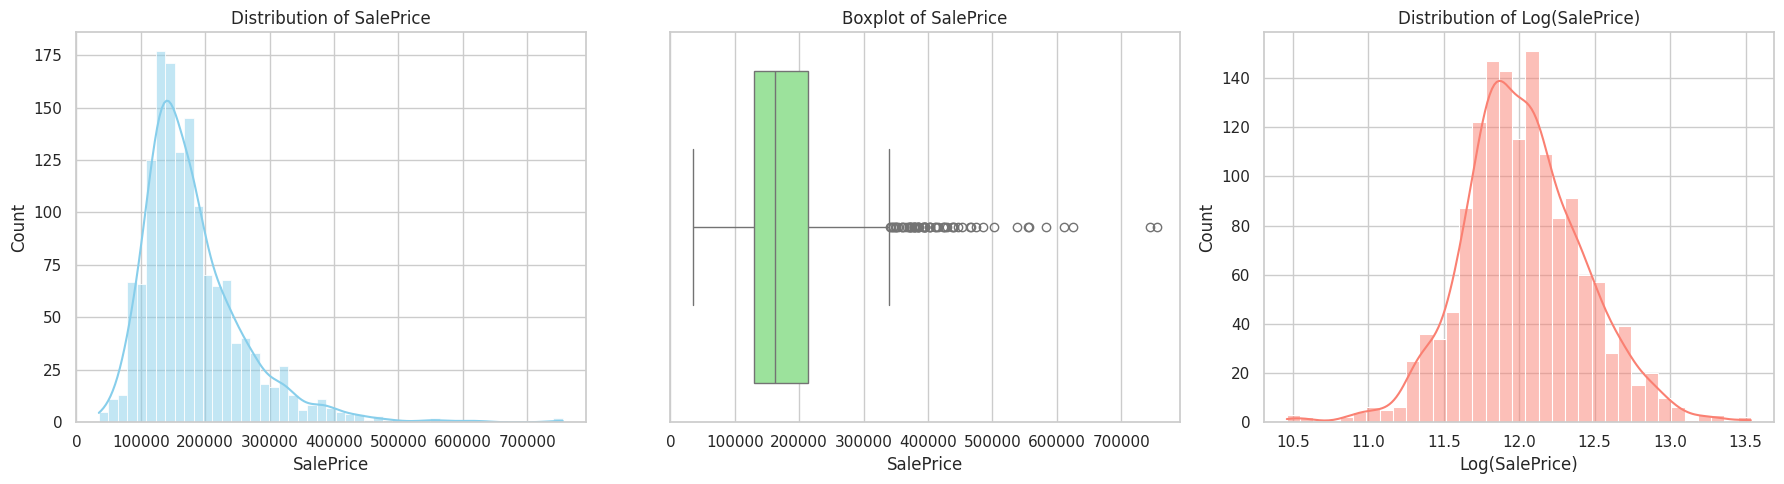

Skewness before Log Transform: 1.8829
Skewness after Log Transform:  0.1213


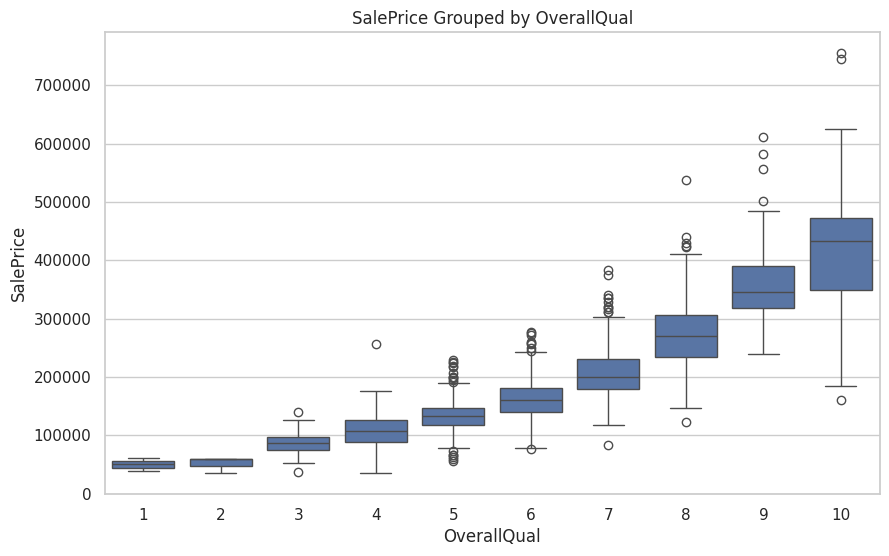

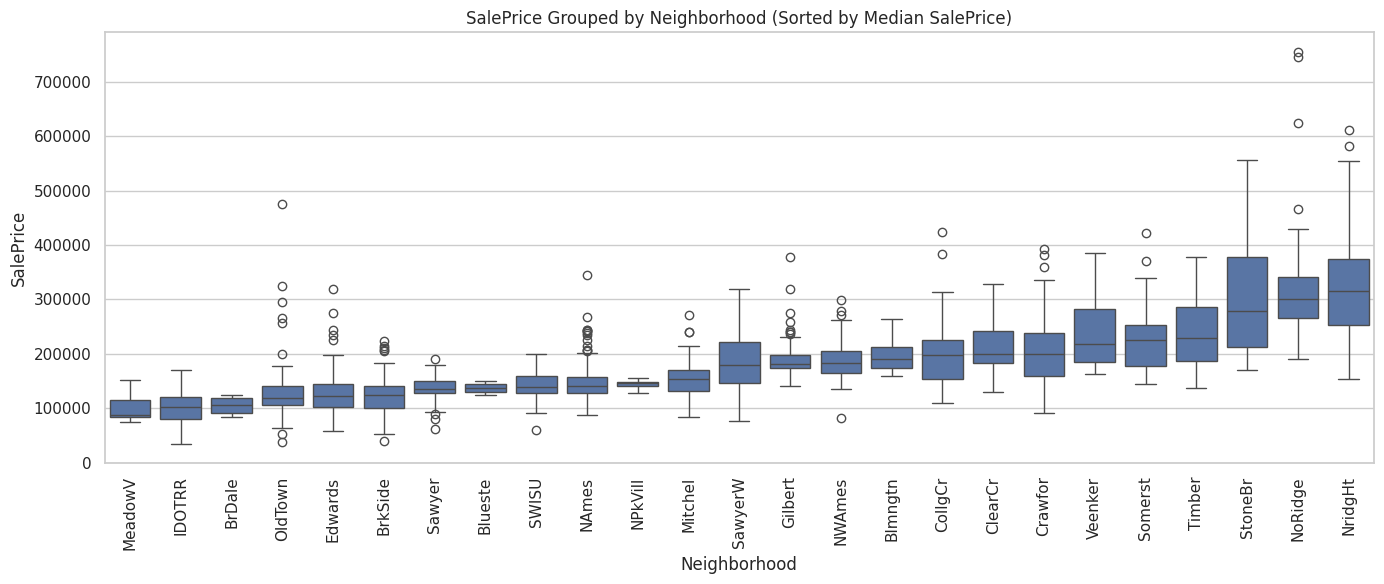

/tmp/ipykernel_1214/2656561701.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='OverallQual', data=df, ax=axes[0], palette='Blues_d')
/tmp/ipykernel_1214/2656561701.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HouseStyle', data=df, ax=axes[1], palette='Purples_d')


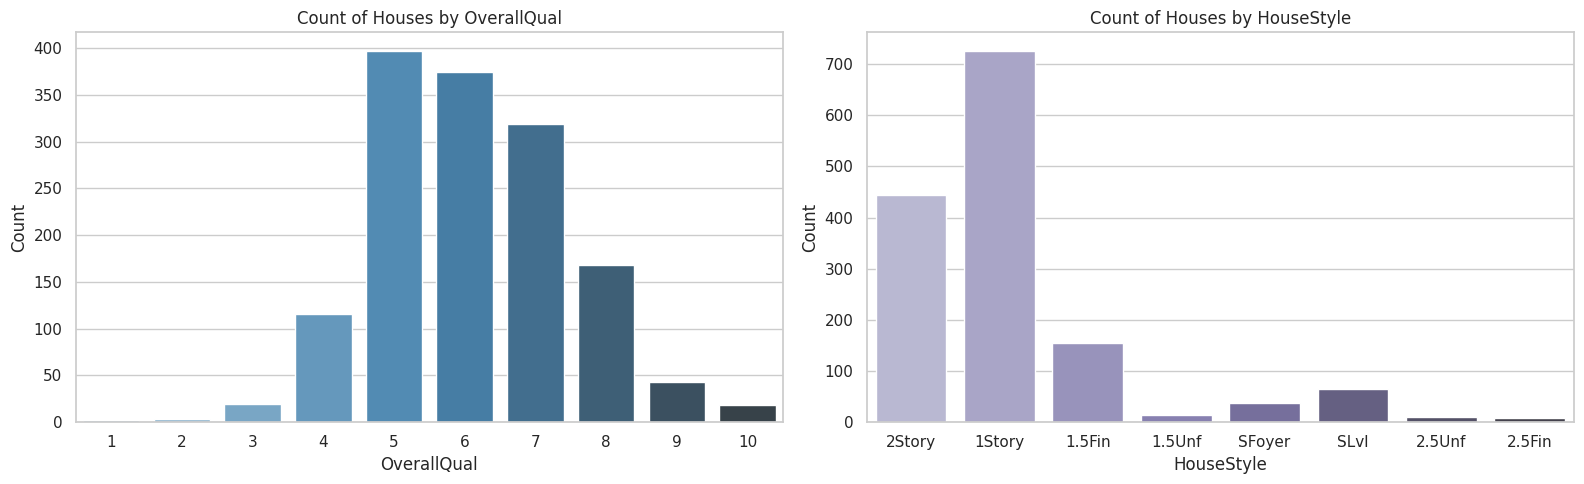

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))


sns.histplot(df['SalePrice'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("SalePrice")
axes[0].set_ylabel("Count")


sns.boxplot(x=df['SalePrice'], ax=axes[1], color='lightgreen')
axes[1].set_title("Boxplot of SalePrice")
axes[1].set_xlabel("SalePrice")


log_saleprice = np.log1p(df['SalePrice'])
sns.histplot(log_saleprice, kde=True, ax=axes[2], color='salmon')
axes[2].set_title("Distribution of Log(SalePrice)")
axes[2].set_xlabel("Log(SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

skew_before = df['SalePrice'].skew()
skew_after = log_saleprice.skew()
print(f"Skewness before Log Transform: {skew_before:.4f}")
print(f"Skewness after Log Transform:  {skew_after:.4f}")


plt.figure(figsize=(10, 6))
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.title("SalePrice Grouped by OverallQual")
plt.xlabel("OverallQual")
plt.ylabel("SalePrice")
plt.show()


plt.figure(figsize=(14, 6))

neighborhood_order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(x='Neighborhood', y='SalePrice', data=df, order=neighborhood_order)
plt.title("SalePrice Grouped by Neighborhood (Sorted by Median SalePrice)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(x='OverallQual', data=df, ax=axes[0], palette='Blues_d')
axes[0].set_title("Count of Houses by OverallQual")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("Count")

sns.countplot(x='HouseStyle', data=df, ax=axes[1], palette='Purples_d')
axes[1].set_title("Count of Houses by HouseStyle")
axes[1].set_xlabel("HouseStyle")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Step 5: Correlation and Covariance
Goal: Find numerical features most related to price.

In [16]:
import pandas as pd
import numpy as np

# 1. Select numeric columns and compute covariance/correlation matrices
numeric_df = df[numeric_cols]
cov_matrix = numeric_df.cov()
corr_matrix = numeric_df.corr(method='pearson')

# 2. Get the top 10 features correlated with SalePrice (by absolute value)
saleprice_corr = corr_matrix['SalePrice']
top_corr_features = saleprice_corr.abs().sort_values(ascending=False).head(11)

print("--- Top 10 Features Correlated with SalePrice ---")
for idx, val in top_corr_features.items():
    if idx != 'SalePrice':
        actual_corr = saleprice_corr[idx]
        print(f"{idx:15} | Correlation: {actual_corr:.4f}")

# 3. For the top 3 correlated features, print covariance and correlation
top_3_features = top_corr_features.index[1:4].tolist()
print("\n--- Covariance vs Correlation for Top 3 Features ---")
for col in top_3_features:
    cov_val = cov_matrix.loc[col, 'SalePrice']
    corr_val = corr_matrix.loc[col, 'SalePrice']
    print(f"{col:15} | Covariance with SalePrice: {cov_val:15.2f} | Correlation: {corr_val:.4f}")

# 4. Explanation
print("\n--- Why Correlation is Easier to Compare than Covariance ---")
print("1. Scale-Independence: Covariance depends entirely on the units and scales of the variables. For example,")
print("   GrLivArea is in square feet (hundreds/thousands) and SalePrice is in dollars (hundreds of thousands),")
print("   resulting in an extremely large covariance value. Correlation normalizes this scale.")
print("2. Standardized Bounds: Correlation is strictly bounded between -1 and +1, making it instantly clear")
print("   how strong and in what direction the linear relationship is, regardless of the variables' original units.")

# 5. Optional: Compute Spearman rank correlation for ordinal columns
print("\n--- Spearman Rank Correlation for Ordinal Columns with SalePrice ---")
ordinal_cols_list = list(ordinal_map.keys())
for col in ordinal_cols_list:
    if col in df.columns:
        # Convert categoricals to their underlying integer codes for numerical ranking
        rank_corr, _ = stats.spearmanr(df[col].cat.codes, df['SalePrice'])
        print(f"{col:15} | Spearman Correlation: {rank_corr:.4f}")

--- Top 10 Features Correlated with SalePrice ---
OverallQual     | Correlation: 0.7910
GrLivArea       | Correlation: 0.7086
GarageCars      | Correlation: 0.6404
GarageArea      | Correlation: 0.6234
TotalBsmtSF     | Correlation: 0.6136
1stFlrSF        | Correlation: 0.6059
FullBath        | Correlation: 0.5607
TotRmsAbvGrd    | Correlation: 0.5337
YearBuilt       | Correlation: 0.5229
YearRemodAdd    | Correlation: 0.5071

--- Covariance vs Correlation for Top 3 Features ---
OverallQual     | Covariance with SalePrice:        86904.13 | Correlation: 0.7910
GrLivArea       | Covariance with SalePrice:     29581866.74 | Correlation: 0.7086
GarageCars      | Covariance with SalePrice:        38020.18 | Correlation: 0.6404

--- Why Correlation is Easier to Compare than Covariance ---
1. Scale-Independence: Covariance depends entirely on the units and scales of the variables. For example,
   GrLivArea is in square feet (hundreds/thousands) and SalePrice is in dollars (hundreds of thousa

Step 6: Scatter Plots and Pair Plots
Goal: Visualise relationships and spot unusual points.

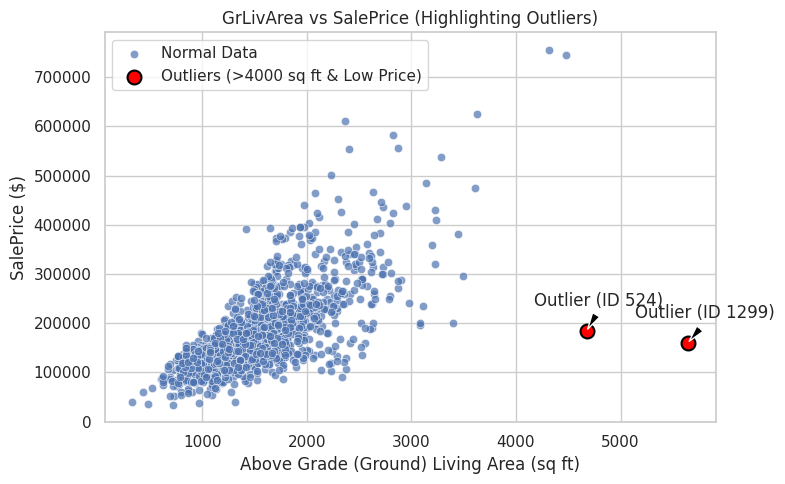

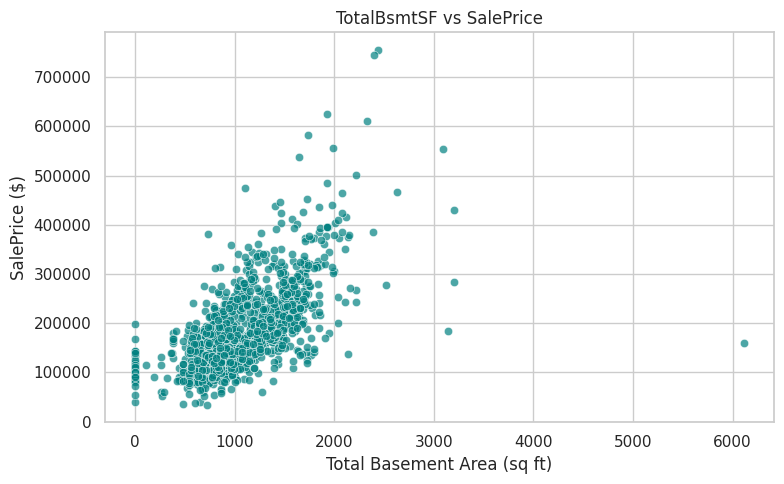

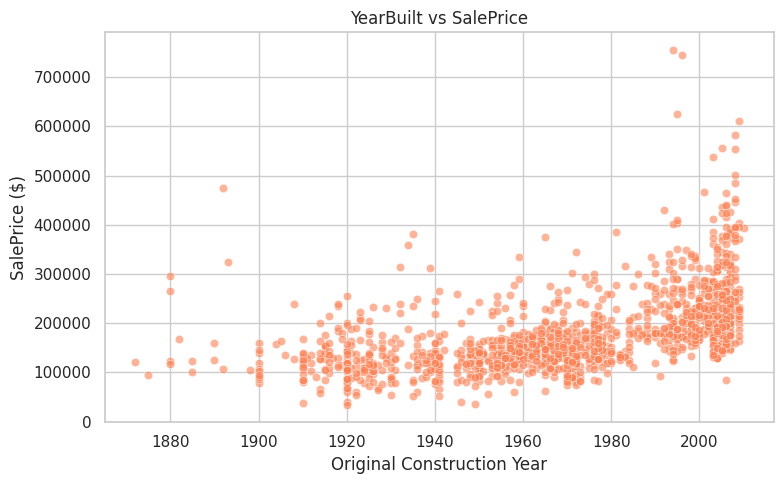

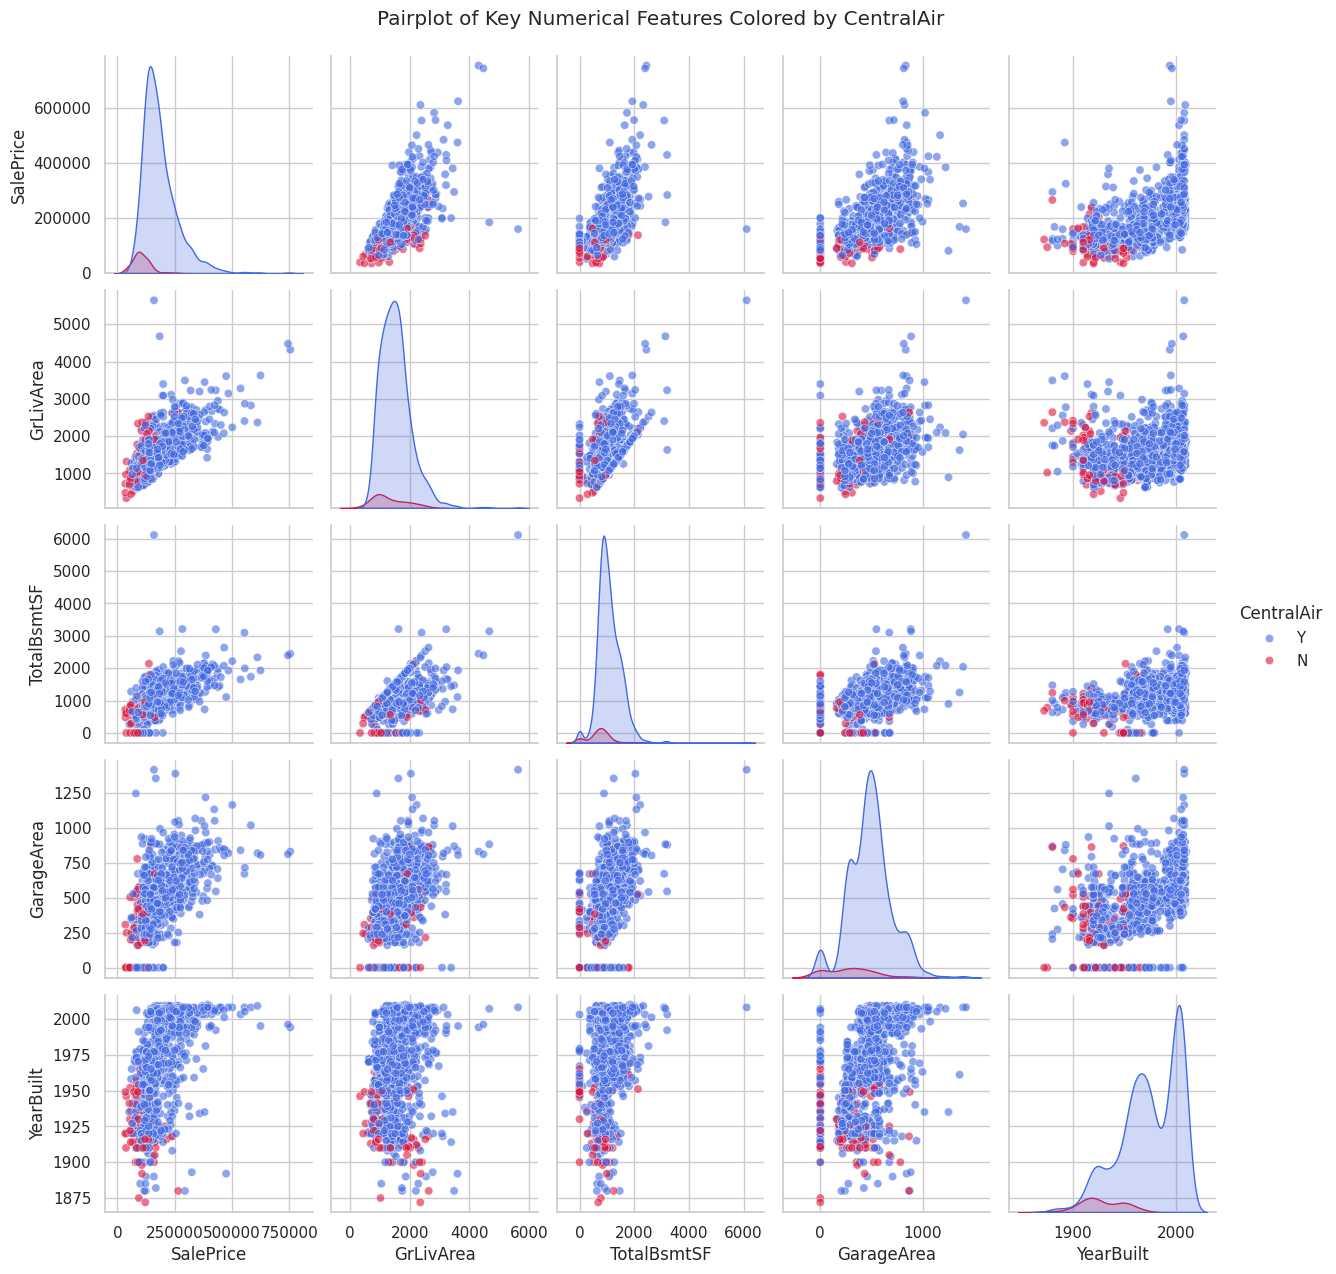

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# --- 1. SCATTER GrLivArea (x) vs SalePrice (y) with Outlier Highlighting ---
plt.figure(figsize=(8, 5))

# Define color condition for points with GrLivArea > 4000 and low price (e.g., SalePrice < 300000)
outliers_cond = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)

# Plot normal points
sns.scatterplot(
    data=df[~outliers_cond],
    x='GrLivArea',
    y='SalePrice',
    alpha=0.7,
    label='Normal Data'
)

# Plot highlighted outliers
sns.scatterplot(
    data=df[outliers_cond],
    x='GrLivArea',
    y='SalePrice',
    color='red',
    s=100,
    edgecolor='black',
    linewidth=1.5,
    label='Outliers (>4000 sq ft & Low Price)'
)

# Annotate the outliers
for idx, row in df[outliers_cond].iterrows():
    plt.annotate(
        f"Outlier (ID {row['Id']})",
        xy=(row['GrLivArea'], row['SalePrice']),
        xytext=(row['GrLivArea'] - 500, row['SalePrice'] + 50000),
        arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6)
    )

plt.title("GrLivArea vs SalePrice (Highlighting Outliers)")
plt.xlabel("Above Grade (Ground) Living Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

# --- 2. SCATTER TotalBsmtSF vs SalePrice ---
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='TotalBsmtSF', y='SalePrice', alpha=0.7, color='teal')
plt.title("TotalBsmtSF vs SalePrice")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

# --- 3. SCATTER YearBuilt vs SalePrice ---
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice', alpha=0.6, color='coral')
plt.title("YearBuilt vs SalePrice")
plt.xlabel("Original Construction Year")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

# --- 4. PAIRPLOT of selected features, colored by CentralAir ---
selected_cols = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', 'CentralAir']

# Create pairplot with diagonal as KDE and colored by CentralAir
g = sns.pairplot(
    df[selected_cols],
    hue='CentralAir',
    palette={'Y': 'royalblue', 'N': 'crimson'},
    diag_kind='kde',
    plot_kws={'alpha': 0.6}
)
g.fig.suptitle("Pairplot of Key Numerical Features Colored by CentralAir", y=1.02)
plt.show()

Step 7: Correlation Heatmap
Goal: One clear picture of feature relationships.

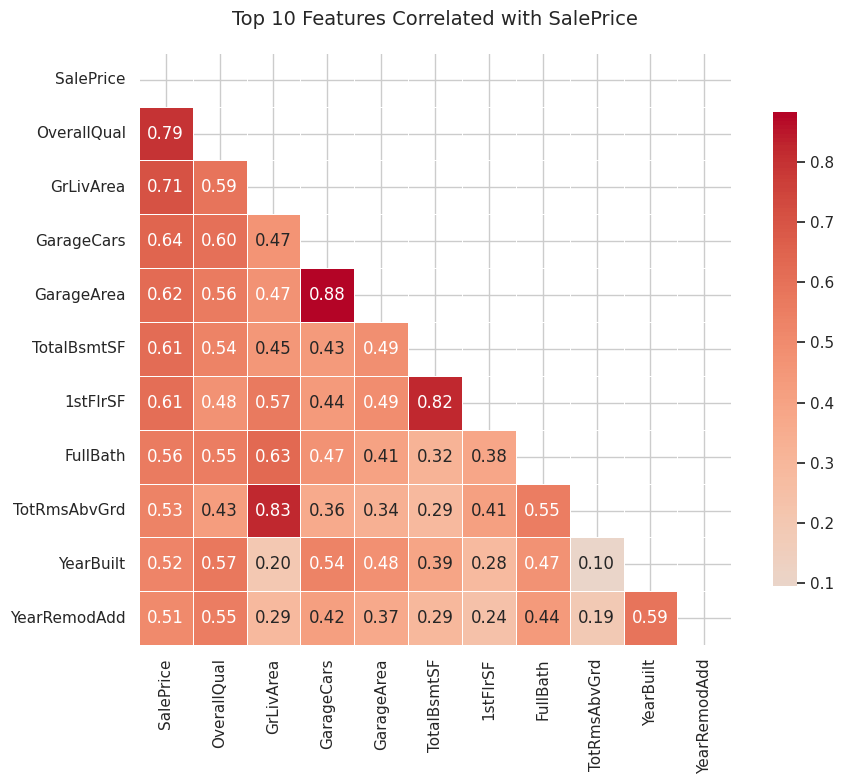

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Get the top 10 features most correlated with SalePrice
top10_cols = top_corr_features.index.tolist()

# 2. Compute the correlation matrix for these top 10 features
corr_top = df[top10_cols].corr()

# 3. Create a mask for the upper triangle to prevent redundant information
mask = np.triu(np.ones_like(corr_top, dtype=bool))

# 4. Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# 5. Plot the heatmap using seaborn
sns.heatmap(
    corr_top,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

# 6. Set the title
plt.title("Top 10 Features Correlated with SalePrice", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

Step 8: Outlier Detection
Goal: Detect outliers with two methods and compare.


Outlier Detection for 'GrLivArea':
  IQR Method count: 31
  Z-score Method count (threshold=3): 16
  Overlap (flagged by both): 16

Outlier Detection for 'SalePrice':
  IQR Method count: 61
  Z-score Method count (threshold=3): 22
  Overlap (flagged by both): 22


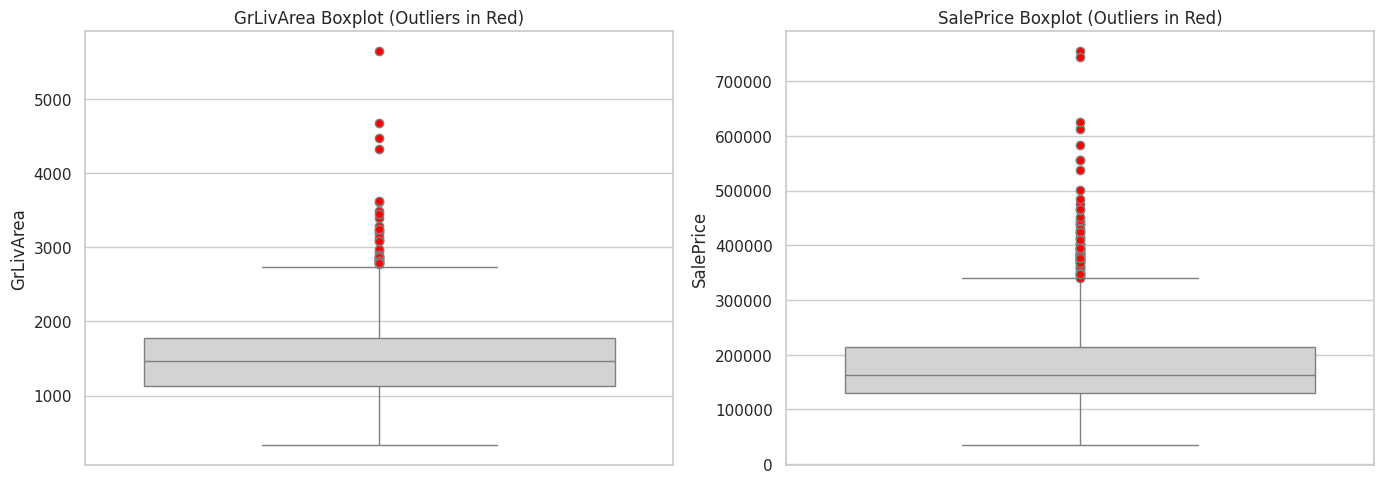

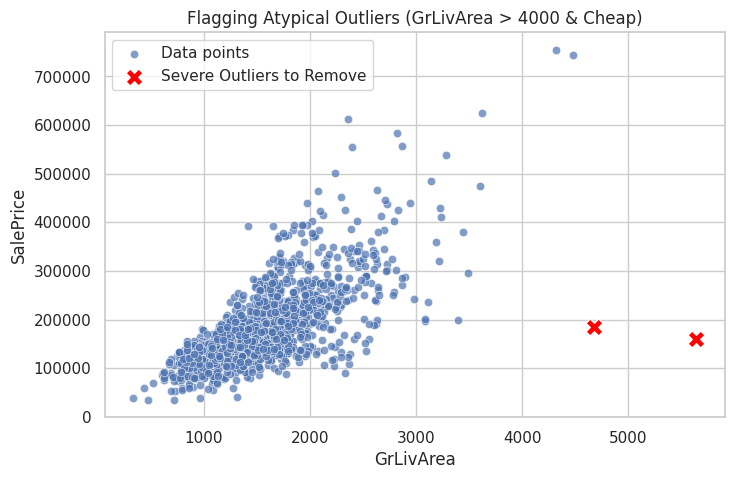


--- Cleaning Dataset ---
Original shape: (1460, 81)
Cleaned shape: (1458, 81) (Removed 2 atypical extreme outliers)


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define the IQR outlier detection function
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

# 2. Define the Z-score outlier detection function
def zscore_outliers(series, threshold=3):
    mean_val = series.mean()
    std_val = series.std()
    z_scores = (series - mean_val) / std_val
    return series[z_scores.abs() > threshold]

# Run detection and compare overlap
for column in ['GrLivArea', 'SalePrice']:
    a_outliers = iqr_outliers(df[column])
    b_outliers = zscore_outliers(df[column])

    overlap = a_outliers.index.intersection(b_outliers.index)

    print(f"\nOutlier Detection for '{column}':")
    print(f"  IQR Method count: {len(a_outliers)}")
    print(f"  Z-score Method count (threshold=3): {len(b_outliers)}")
    print(f"  Overlap (flagged by both): {len(overlap)}")

# 3. Show Boxplots with outliers marked
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y='GrLivArea', ax=axes[0], color='lightgray', flierprops=dict(markerfacecolor='red', marker='o'))
axes[0].set_title("GrLivArea Boxplot (Outliers in Red)")

sns.boxplot(data=df, y='SalePrice', ax=axes[1], color='lightgray', flierprops=dict(markerfacecolor='red', marker='o'))
axes[1].set_title("SalePrice Boxplot (Outliers in Red)")
plt.tight_layout()
plt.show()

# 4. Scatter plot showing flagged outliers (GrLivArea > 4000 and low price)
plt.figure(figsize=(8, 5))
atypical_outliers_cond = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
atypical_outliers = df[atypical_outliers_cond]

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', alpha=0.7, label='Data points')
sns.scatterplot(data=atypical_outliers, x='GrLivArea', y='SalePrice', color='red', s=150, marker='X', label='Severe Outliers to Remove')
plt.title("Flagging Atypical Outliers (GrLivArea > 4000 & Cheap)")
plt.xlabel("GrLivArea")
plt.ylabel("SalePrice")
plt.legend()
plt.show()

# 5. Decide and clean
# As recommended by Ames Housing Documentation: remove houses with GrLivArea > 4000 with cheap prices.
print("\n--- Cleaning Dataset ---")
print(f"Original shape: {df.shape}")
df_clean = df[~atypical_outliers_cond].copy()
print(f"Cleaned shape: {df_clean.shape} (Removed {len(atypical_outliers)} atypical extreme outliers)")

Step 9: Data Quality Checks
Goal: Find duplicates, inconsistent labels, and misleading missing values.

In [20]:
import pandas as pd
import numpy as np

# We will perform data quality checks on our cleaned dataset: df_clean
df_qc = df_clean.copy()

# 1. Check and remove duplicate rows
dup_count = df_qc.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")
if dup_count > 0:
    df_qc = df_qc.drop_duplicates()
    print(f"Duplicates removed. New dataset shape: {df_qc.shape}")

# 2. Standardise and check categorical columns for whitespace/casing consistency
print("\n--- Standardising Categorical Columns ---")
categorical_cols = df_qc.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    # Strip whitespace
    df_qc[col] = df_qc[col].astype(str).str.strip()

    # Temporary check for lowercase/uppercase inconsistencies
    # If we find both lowercase and titlecase versions (e.g., 'gd' and 'Gd'), we standardise them
    unique_vals = df_qc[col].unique()
    unique_lower = [v.lower() for v in unique_vals]
    if len(unique_vals) != len(set(unique_lower)):
        print(f"Inconsistent casing found in '{col}'. Standardising to Title Case...")
        df_qc[col] = df_qc[col].str.title()

# 3. Replace meaningful Nulls in specific categorical columns with "None"
none_fill_cols = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
for col in none_fill_cols:
    if col in df_qc.columns:
        df_qc[col] = df_qc[col].replace('nan', np.nan) # convert str 'nan' back if converted by astype(str)
        df_qc[col] = df_qc[col].fillna('None')
print(f"Replaced missing categories with 'None' for: {none_fill_cols}")

# 4. Fill missing numerical values
# Fill LotFrontage with median of its Neighborhood
if 'LotFrontage' in df_qc.columns:
    df_qc['LotFrontage'] = df_qc.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
    print("Filled missing 'LotFrontage' using the median of each Neighborhood.")

# Fill remaining numeric nulls with their respective column median (or 0 if appropriate like MasVnrArea)
remaining_numeric_nulls = df_qc.select_dtypes(include=['number']).isnull().sum()
for col, count in remaining_numeric_nulls.items():
    if count > 0:
        median_val = df_qc[col].median()
        df_qc[col] = df_qc[col].fillna(median_val)
        print(f"Filled missing values in numeric column '{col}' with median: {median_val}")

# 5. Verify remaining missing count
missing_after = df_qc.isnull().sum().sum()
print(f"\nRemaining missing values in dataset: {missing_after}")

# 6. Check for impossible/illogical value bounds
impossible_years = df_qc[df_qc['YearBuilt'] > df_qc['YrSold']]
print(f"Houses built after being sold: {len(impossible_years)}")
if len(impossible_years) > 0:
    display(impossible_years[['Id', 'YearBuilt', 'YrSold']])

negative_areas = df_qc[(df_qc['GrLivArea'] < 0) | (df_qc['TotalBsmtSF'] < 0) | (df_qc['LotArea'] < 0)]
print(f"Houses with negative square footage or areas: {len(negative_areas)}")

Number of duplicated rows: 0

--- Standardising Categorical Columns ---
Replaced missing categories with 'None' for: ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'MasVnrType']
Filled missing 'LotFrontage' using the median of each Neighborhood.
Filled missing values in numeric column 'MasVnrArea' with median: 0.0
Filled missing values in numeric column 'GarageYrBlt' with median: 1980.0

Remaining missing values in dataset: 0
Houses built after being sold: 0
Houses with negative square footage or areas: 0


 Step 10: Final Dashboard and Storytelling
Goal: Combine the best visuals into one clean figure and write conclusions.

/tmp/ipykernel_1214/3152178168.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_neighborhoods, x='SalePrice', y='Neighborhood', ax=axes[0, 1], palette='Blues_r')


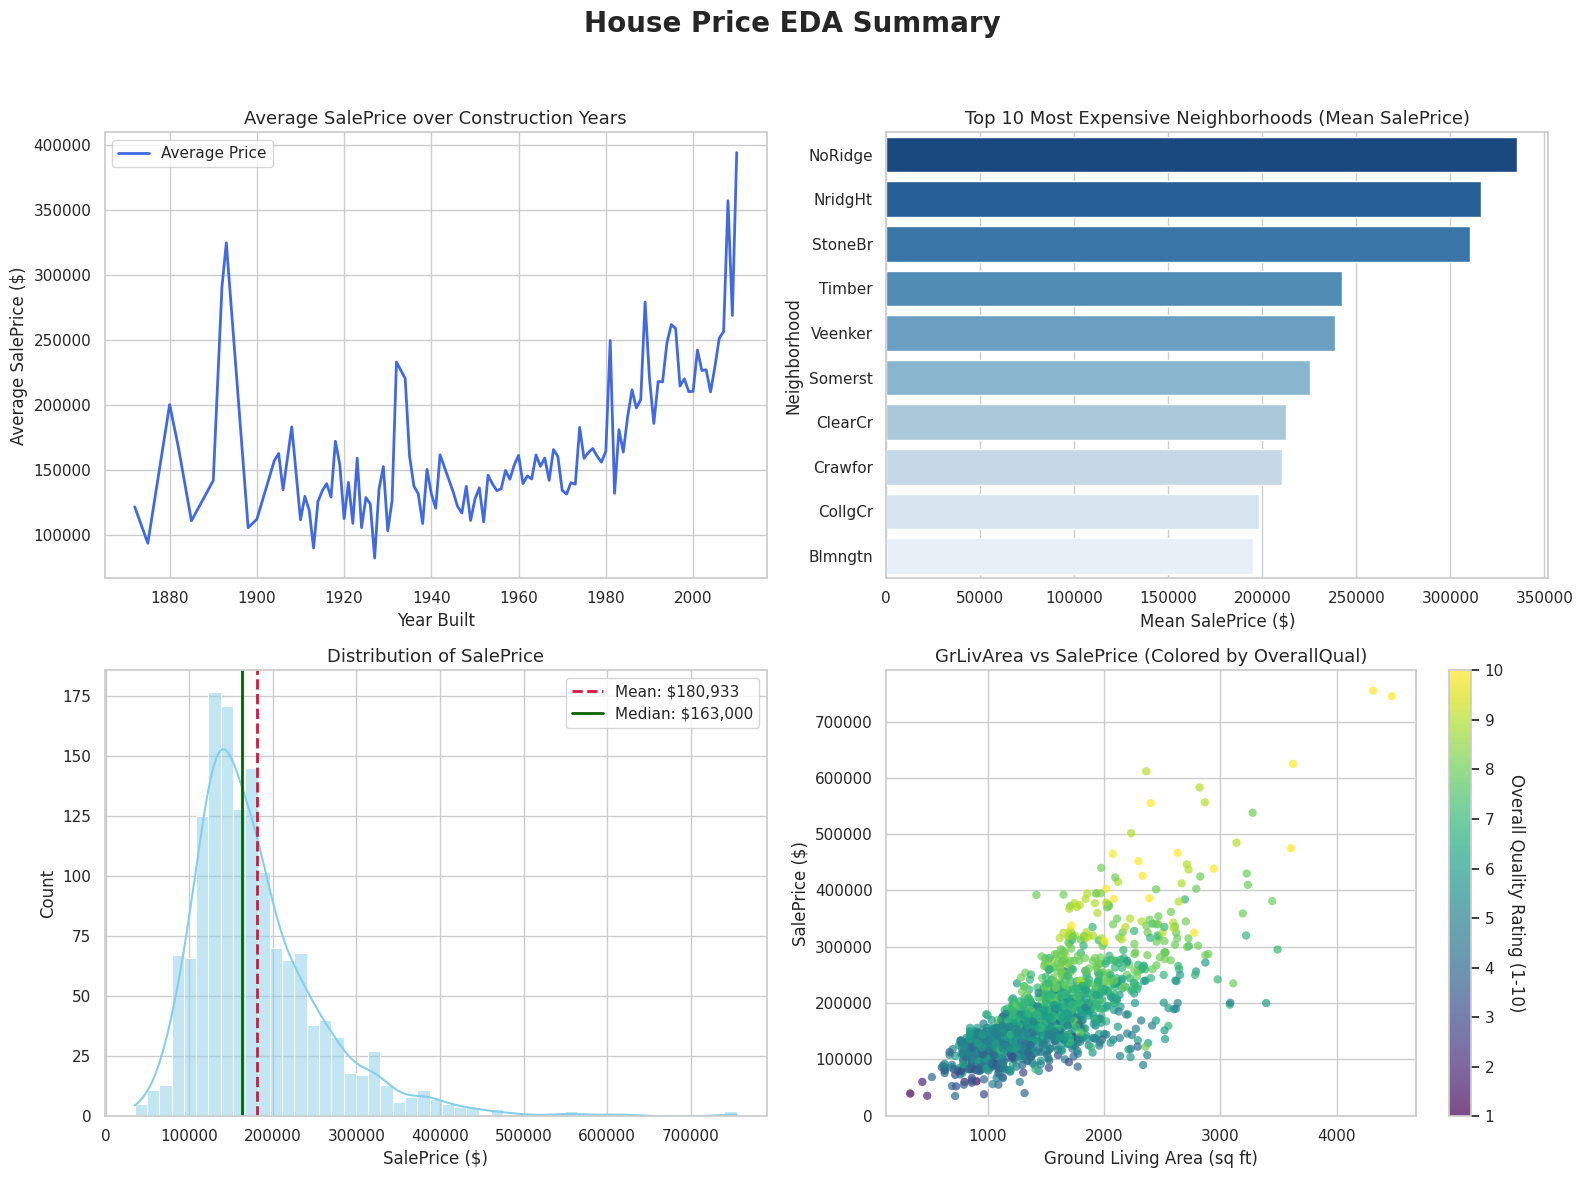

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set consistent style
sns.set_theme(style="whitegrid")

# Create a 2x2 grid figure
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("House Price EDA Summary", fontsize=20, fontweight='bold', y=0.98)

# Panel 1: Line plot of Average SalePrice by YearBuilt
year_price = df_qc.groupby('YearBuilt')['SalePrice'].mean().reset_index()
axes[0, 0].plot(year_price['YearBuilt'], year_price['SalePrice'], color='royalblue', linewidth=2, label='Average Price')
axes[0, 0].set_title("Average SalePrice over Construction Years", fontsize=13)
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average SalePrice ($)")
axes[0, 0].legend()

# Panel 2: Bar plot of Top 10 Most Expensive Neighborhoods
top_neighborhoods = df_qc.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False).head(10).reset_index()
sns.barplot(data=top_neighborhoods, x='SalePrice', y='Neighborhood', ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title("Top 10 Most Expensive Neighborhoods (Mean SalePrice)", fontsize=13)
axes[0, 1].set_xlabel("Mean SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: SalePrice Distribution with Mean & Median markers
sns.histplot(df_qc['SalePrice'], kde=True, ax=axes[1, 0], color='skyblue')
mean_price = df_qc['SalePrice'].mean()
median_price = df_qc['SalePrice'].median()
axes[1, 0].axvline(mean_price, color='crimson', linestyle='--', linewidth=2, label=f'Mean: ${mean_price:,.0f}')
axes[1, 0].axvline(median_price, color='darkgreen', linestyle='-', linewidth=2, label=f'Median: ${median_price:,.0f}')
axes[1, 0].set_title("Distribution of SalePrice", fontsize=13)
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4: Scatter plot of GrLivArea vs SalePrice colored by OverallQual
scatter = axes[1, 1].scatter(
    df_qc['GrLivArea'],
    df_qc['SalePrice'],
    c=df_qc['OverallQual'],
    cmap='viridis',
    alpha=0.7,
    edgecolors='none'
)
axes[1, 1].set_title("GrLivArea vs SalePrice (Colored by OverallQual)", fontsize=13)
axes[1, 1].set_xlabel("Ground Living Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")
# Add colorbar matching overall quality
cbar = fig.colorbar(scatter, ax=axes[1, 1])
cbar.set_label('Overall Quality Rating (1-10)', rotation=270, labelpad=15)

# Adjust layout and save
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("eda_dashboard.png", dpi=300)
plt.show()